# FTWP Chapter 3 — Review and Exercises

This notebook consolidates the **six non-capstone tasks** for FTWP Chapter 3:
three review exercises and three regular exercises. The problem statements are
paraphrased from the CPF exercise sheet. Numerical parameters are stated where
the source task leaves them open.

The notebook is designed to run from top to bottom in Google Colab or a standard
Python/Jupyter environment.

In [1]:
%matplotlib inline

## Review exercises

### 1. Why two assets generally cannot span three states

Two payoff vectors span a subspace of dimension at most two, while the full
three-state claim space is $\mathbb R^3$. Unless a claim lies in that subspace,
it is unattainable.

### 2. Least-squares replication

For an unattainable claim, compute

$$\hat\phi=\arg\min_\phi\|C_1-M\phi\|_2$$

and residual $e=C_1-M\hat\phi$.

### 3. Economic interpretation

The residual is the claim component left unhedged by the traded assets.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

states = ["Up", "Middle", "Down"]
B0, S0 = 10.0, 10.0
B1 = np.array([11.0, 11.0, 11.0])
S1 = np.array([20.0, 10.0, 5.0])
M0 = np.array([B0, S0])
M = np.column_stack((B1, S1))

C1 = np.array([1.0, 0.0, 0.0])
phi_ls, *_ = np.linalg.lstsq(M, C1, rcond=None)
projection = M @ phi_ls
residual = C1 - projection

print("rank(M):", np.linalg.matrix_rank(M))
print("Least-squares holdings:", phi_ls)
print("Projection:", projection)
print("Residual:", residual)
print("Residual norm:", np.linalg.norm(residual))
print("Orthogonal to traded payoffs:", np.allclose(M.T @ residual, 0.0))

rank(M): 2
Least-squares holdings: [-0.04545455  0.07142857]
Projection: [ 0.92857143  0.21428571 -0.14285714]
Residual: [ 0.07142857 -0.21428571  0.14285714]
Residual norm: 0.2672612419124244
Orthogonal to traded payoffs: True


## Regular exercises

### 4. Project several claims onto the attainable subspace

I project the three Arrow-Debreu unit claims. Their residual norms show how
strongly each claim points in the one payoff direction missing from the market.

### 5. Martingale-measure prices and bounds

All measures satisfying the traded-asset restrictions have the form

$$Q(q)=\left(q,\;\frac65-3q,\;2q-\frac15\right).$$

If all three physical states are possible, an **equivalent** martingale measure
must be strictly positive, so $0.1<q<0.4$. For the Up-state claim, the
arbitrage-free prices are therefore strictly between $1/11$ and $4/11$.
The endpoints are limiting bounds generated by nonnegative measures with a zero
state probability; they are not interior arbitrage-free prices for a freely
traded new claim under full support.

In [3]:
claims = {
    "Up unit claim": np.array([1.0, 0.0, 0.0]),
    "Middle unit claim": np.array([0.0, 1.0, 0.0]),
    "Down unit claim": np.array([0.0, 0.0, 1.0]),
}

projection_rows = []
for name, claim in claims.items():
    holdings, *_ = np.linalg.lstsq(M, claim, rcond=None)
    fitted = M @ holdings
    err = claim - fitted
    projection_rows.append(
        {"Claim": name, "Residual norm": np.linalg.norm(err), "Largest absolute state error": np.max(np.abs(err))}
    )

projection_table = pd.DataFrame(projection_rows).set_index("Claim")
display(projection_table)

def martingale_measure(q_up):
    return np.array([q_up, 6.0 / 5.0 - 3.0 * q_up, 2.0 * q_up - 1.0 / 5.0])

r = 0.10
q_candidates = np.array([0.15, 0.25, 0.35])
candidate_rows = []

for q_up in q_candidates:
    Q = martingale_measure(q_up)
    candidate_rows.append(
        {
            "q_up": q_up,
            "q_middle": Q[1],
            "q_down": Q[2],
            "Claim price": (Q @ C1) / (1.0 + r),
            "E_Q[S1]": Q @ S1,
        }
    )

candidate_table = pd.DataFrame(candidate_rows)
display(candidate_table)

limiting_lower = 1.0 / 11.0
limiting_upper = 4.0 / 11.0
print(f"Strict arbitrage-free interval: ({limiting_lower:.6f}, {limiting_upper:.6f})")

,Residual norm,Largest absolute state error
Claim,,
Up unit claim,0.267261,0.214286
Middle unit claim,0.801784,0.642857
Down unit claim,0.534522,0.428571


,q_up,q_middle,q_down,Claim price,E_Q[S1]
0,0.15,0.75,0.1,0.136364,11.0
1,0.25,0.45,0.3,0.227273,11.0
2,0.35,0.15,0.5,0.318182,11.0


Strict arbitrage-free interval: (0.090909, 0.363636)


### 6. Mean-variance quantities and a simple security market line

Using physical probabilities $P=(0.3,0.4,0.3)$, I calculate expected returns
and the probability-weighted covariance matrix for three illustrative risky
securities. The equal-weighted risky portfolio is used as the market proxy.
The ordinary least-squares fit is

$$E[R_i]-R_f=\alpha+\beta_i\lambda+\varepsilon_i,$$

where $\beta_i=\operatorname{Cov}(R_i,R_m)/\operatorname{Var}(R_m)$.

,Expected gross return,Beta,Expected excess return,OLS fitted excess return
Asset A,1.03,1.000000,-0.02,-0.02
Asset B,1.04,0.550607,-0.01,-0.01
Asset C,1.02,1.449393,-0.03,-0.03


Probability-weighted return covariance matrix:
[[0.0741 0.0408 0.1074]
 [0.0408 0.0264 0.0552]
 [0.1074 0.0552 0.1596]]
Security market line: excess return = 0.00225 + -0.02225 beta


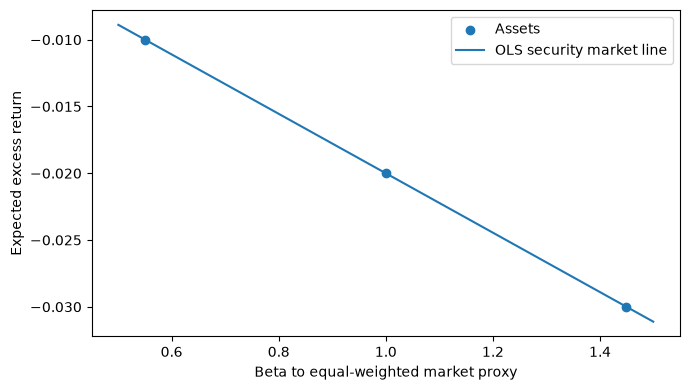

In [4]:
P = np.array([0.30, 0.40, 0.30])
prices = np.array([10.0, 10.0, 10.0])
payoffs = np.array(
    [
        [14.0, 12.0, 16.0],  # Up
        [10.0, 11.0, 9.0],   # Middle
        [7.0, 8.0, 6.0],     # Down
    ]
)

returns = payoffs / prices
expected_returns = P @ returns
centered = returns - expected_returns
covariance = centered.T @ (P[:, None] * centered)

market_returns = returns.mean(axis=1)
expected_market = P @ market_returns
market_var = P @ (market_returns - expected_market) ** 2
betas = np.array(
    [P @ ((returns[:, i] - expected_returns[i]) * (market_returns - expected_market)) / market_var for i in range(3)]
)

R_f = 1.05
excess_returns = expected_returns - R_f
design = np.column_stack((np.ones_like(betas), betas))
alpha, slope = np.linalg.lstsq(design, excess_returns, rcond=None)[0]
fitted_excess = design @ np.array([alpha, slope])

sml_table = pd.DataFrame(
    {
        "Expected gross return": expected_returns,
        "Beta": betas,
        "Expected excess return": excess_returns,
        "OLS fitted excess return": fitted_excess,
    },
    index=["Asset A", "Asset B", "Asset C"],
)

display(sml_table)
print("Probability-weighted return covariance matrix:")
print(covariance)
print(f"Security market line: excess return = {alpha:.5f} + {slope:.5f} beta")

plt.figure(figsize=(7, 4))
plt.scatter(betas, excess_returns, label="Assets")
beta_grid = np.linspace(betas.min() - 0.05, betas.max() + 0.05, 100)
plt.plot(beta_grid, alpha + slope * beta_grid, label="OLS security market line")
plt.xlabel("Beta to equal-weighted market proxy")
plt.ylabel("Expected excess return")
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
checks = {
    "two assets do not span R3": np.linalg.matrix_rank(M) == 2,
    "least-squares orthogonality": np.allclose(M.T @ residual, 0.0),
    "projection decomposition": np.allclose(C1, projection + residual),
    "candidate measures positive": all(np.all(martingale_measure(q) > 0) for q in q_candidates),
    "candidate measures sum to one": all(np.isclose(martingale_measure(q).sum(), 1.0) for q in q_candidates),
    "candidate stock martingale restriction": np.allclose(candidate_table["E_Q[S1]"], 11.0),
    "covariance symmetric": np.allclose(covariance, covariance.T),
    "market variance positive": market_var > 0,
}

for name, passed in checks.items():
    print(f"{name}: {passed}")
assert all(checks.values())

two assets do not span R3: True
least-squares orthogonality: True
projection decomposition: True
candidate measures positive: True
candidate measures sum to one: True
candidate stock martingale restriction: True
covariance symmetric: True
market variance positive: True
